# Nadeau-Bengio Corrected Resampled t-Test — Mix Dataset (PoI, 306 features)

**Why this test, specifically**: this project evaluates every model across 10
independent random 80:20 stratified splits of the *same* fixed 426-sample dataset. A
naive paired t-test on the 10 per-seed performance differences between two models
assumes those 10 differences are statistically independent. They are not — every split
draws its training set from the same pool of 426 samples, so the 10 training sets
overlap heavily with each other. That overlap induces positive correlation between the
10 performance estimates, which a standard t-test's variance formula does not account
for. The practical consequence is well documented
\citep{nadeau2003inference}: **the naive t-test's p-values are too small**, so it finds
"significant" differences between models more often than it should (an inflated
Type I error rate).

Nadeau & Bengio (2003) derived a corrected variance estimator specifically for repeated
random train/test splits (not k-fold CV) that adds a term proportional to the
test/train size ratio, which restores a valid (conservative) test.

## The correction

For $k=10$ seeds, let $d_i$ = (Model A balanced accuracy $-$ Model B balanced accuracy)
on seed $i$, $\bar{d}$ = mean of the $d_i$, and $s^2$ = their sample variance ($\text{ddof}=1$).
With $n_{test}=86$ and $n_{train}=340$ (constant across all 10 seeds in this project):

$$
t = \frac{\bar{d}}{\sqrt{\left(\frac{1}{k} + \frac{n_{test}}{n_{train}}\right) s^2}}
\qquad \text{compared against a } t\text{-distribution with } k-1 \text{ degrees of freedom.}
$$

The $n_{test}/n_{train}$ term (here, $86/340 \approx 0.253$) is the correction itself — it
is always $\geq 0$, so the corrected test statistic is always smaller in magnitude (more
conservative) than the naive one, which uses only $1/k$.

## How this complements the Friedman/Wilcoxon analysis

Friedman and Wilcoxon signed-rank (the project's primary significance tests) are
rank-based and non-parametric — they do not assume the per-seed differences are
normally distributed, but they also do not explicitly model the resampling correlation
the way Nadeau-Bengio does. Running both is a robustness check: if a pairwise comparison
is significant under **both** a rank-based test and a variance-corrected parametric
test built for this exact resampling design, that is stronger evidence than either test
alone. Where they disagree, the reason is usually informative (e.g. a non-normal
difference distribution, or a borderline effect that one test's conservatism catches
and the other's doesn't).

In [1]:
import os, sys, json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from itertools import combinations
from statsmodels.stats.multitest import multipletests

_cwd = os.getcwd()
ROOT = _cwd
for _c in [_cwd] + [os.path.abspath(os.path.join(_cwd, *['..'] * i)) for i in range(1, 4)]:
    if os.path.isdir(os.path.join(_c, 'scripts')) and os.path.isdir(os.path.join(_c, 'Mix_Results_PoI')):
        ROOT = _c
        break

sys.path.insert(0, os.path.join(ROOT, 'scripts'))
from model_colors import MODEL_COLORS, MODEL_LABELS

RESULTS = 'Mix_Results_PoI'
FIG_DIR = os.path.join(ROOT, RESULTS, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

%matplotlib inline
plt.rcParams.update({'figure.dpi': 130, 'font.family': 'sans-serif'})

SEEDS = [42, 123, 456, 789, 1011, 1213, 1415, 1617, 1819, 2021]
N_TEST, N_TRAIN = 86, 340   # constant across all 10 seeds (verified: 426 total, 80:20 stratified split)

print('Project root:', ROOT)

Project root: C:\Users\DT User\Documents\GitHub\ML_in_LTDNA


## 1  Load per-seed balanced accuracy at each model's best strategy

Same "best strategy per model" set reported in the paper's Table 1 — this test asks
whether the *paper's own headline comparisons* are statistically defensible once the
resampling correlation is accounted for.

In [2]:
# (model_key, best strategy, display label) — matches paper Table 1
MODELS = [
    ('tabpfn',              'ClassWeights',      'TabPFN 3.5'),
    ('extratrees',          'SMOTE',             'Extra Trees'),
    ('randomforest',        'SMOTE',             'Random Forest'),
    ('lgbm',                'SMOTE',             'LightGBM'),
    ('xgboost',             'SMOTE',             'XGBoost'),
    ('mlp',                 'SMOTE',             'MLP'),
    ('logistic_regression', 'ClassWeights',      'LR'),
    ('svm',                 'SMOTE',             'SVM'),
    ('gnb',                 'Original',          'GNB'),
]

records = []
for seed in SEEDS:
    std_path = (os.path.join(ROOT, RESULTS, 'reports', 'combined_results.json')
                if seed == 42 else
                os.path.join(ROOT, RESULTS, f'seed_{seed}', 'reports', 'combined_results.json'))
    with open(std_path) as f:
        std_data = json.load(f)

    v3_path = (os.path.join(ROOT, RESULTS, 'reports', 'combined_results_v35.json')
               if seed == 42 else
               os.path.join(ROOT, RESULTS, f'seed_{seed}_v35', 'reports', 'combined_results_v35.json'))
    with open(v3_path) as f:
        v3_data = json.load(f)

    for model_key, strategy, label in MODELS:
        src = v3_data if model_key == 'tabpfn' else std_data
        ba = src[model_key]['results'][strategy]['balanced_accuracy']
        records.append({'model': label, 'seed': seed, 'BA': ba})

df = pd.DataFrame(records)
pivot = df.pivot(index='seed', columns='model', values='BA')
model_order = [label for _, _, label in MODELS]
pivot = pivot[model_order]
print('Shape:', pivot.shape, '(should be 10 seeds x 9 models)')
pivot.round(4)

Shape: (10, 9) (should be 10 seeds x 9 models)


model,TabPFN 3.5,Extra Trees,Random Forest,LightGBM,XGBoost,MLP,LR,SVM,GNB
seed,,,,,,,,,
42,0.9010,0.8317,0.8022,0.8206,0.8341,0.7443,0.7522,0.6179,0.5159
123,0.9566,0.8328,0.7772,0.8830,0.8261,0.7543,0.7699,0.6957,0.5884
456,0.8234,0.8345,0.7828,0.8012,0.7588,0.7790,0.7221,0.6368,0.5953
789,0.9344,0.9344,0.8598,0.7633,0.6981,0.7804,0.7464,0.7058,0.5322
1011,0.8386,0.7827,0.7879,0.7650,0.7254,0.6814,0.7800,0.7320,0.4743
1213,0.8001,0.8112,0.7644,0.7238,0.7515,0.6793,0.7227,0.6911,0.5217
1415,0.8435,0.7509,0.7727,0.8810,0.8463,0.7807,0.7685,0.6134,0.6911
1617,0.9389,0.8116,0.8469,0.8191,0.8542,0.7408,0.7099,0.6374,0.5425
1819,0.7995,0.7481,0.7838,0.7699,0.7481,0.7058,0.6634,0.6714,0.5812


## 2  Nadeau-Bengio corrected t-test implementation

In [3]:
def nadeau_bengio_ttest(a, b, n_test=N_TEST, n_train=N_TRAIN):
    """Corrected resampled t-test (Nadeau & Bengio, 2003) for two paired samples of
    per-seed performance (a, b), each of length k (number of resampled splits).
    Returns (t_statistic, p_value_two_sided, mean_diff, corrected_std, naive_p_value).
    """
    a, b = np.asarray(a), np.asarray(b)
    d = a - b
    k = len(d)
    mean_d = d.mean()
    var_d = d.var(ddof=1)

    correction = (1.0 / k) + (n_test / n_train)
    corrected_var = correction * var_d
    corrected_std = np.sqrt(corrected_var)

    if corrected_std == 0:
        t_stat = 0.0 if mean_d == 0 else np.inf * np.sign(mean_d)
    else:
        t_stat = mean_d / corrected_std
    df_ = k - 1
    p_value = 2 * (1 - stats.t.cdf(abs(t_stat), df=df_))

    # Naive (textbook, uncorrected) paired t-test for comparison
    naive_t, naive_p = stats.ttest_rel(a, b)

    return {
        't_statistic': t_stat, 'p_value': p_value, 'df': df_,
        'mean_diff': mean_d, 'corrected_std': corrected_std,
        'naive_t': naive_t, 'naive_p': naive_p,
    }


# Sanity check against the naive test using two clearly-different columns
demo = nadeau_bengio_ttest(pivot['TabPFN 3.5'].values, pivot['GNB'].values)
print('Demo: TabPFN vs GNB')
print(f"  Corrected: t={demo['t_statistic']:.3f}, p={demo['p_value']:.6f}")
print(f"  Naive:     t={demo['naive_t']:.3f}, p={demo['naive_p']:.6f}")
print(f"  -> corrected p is larger (test is more conservative), as expected.")

Demo: TabPFN vs GNB
  Corrected: t=5.757, p=0.000274
  Naive:     t=10.815, p=0.000002
  -> corrected p is larger (test is more conservative), as expected.


## 3  All pairwise comparisons (36 pairs), Holm-corrected

Same multiple-comparison correction approach (Holm, across all pairwise tests) used for
the Wilcoxon analysis, applied here to the Nadeau-Bengio p-values instead.

In [4]:
pairs = list(combinations(model_order, 2))
rows = []
for a_name, b_name in pairs:
    res = nadeau_bengio_ttest(pivot[a_name].values, pivot[b_name].values)
    winner = a_name if res['mean_diff'] > 0 else b_name
    rows.append({
        'Model A': a_name, 'Model B': b_name,
        'Mean A': pivot[a_name].mean(), 'Mean B': pivot[b_name].mean(),
        'Mean diff (A-B)': res['mean_diff'],
        't (corrected)': res['t_statistic'], 'p_raw': res['p_value'],
        't (naive)': res['naive_t'], 'p_naive': res['naive_p'],
        'Winner': winner,
    })

pw = pd.DataFrame(rows)
reject, p_adj, _, _ = multipletests(pw['p_raw'], method='holm')
pw['p_adj (Holm)'] = p_adj
pw['Significant'] = reject

# How many pairs would have been "significant" under the naive test but are NOT under
# the corrected one (after the same Holm procedure)?
reject_naive, p_adj_naive, _, _ = multipletests(pw['p_naive'], method='holm')
pw['Significant (naive, Holm)'] = reject_naive

display_cols = ['Model A', 'Model B', 'Mean diff (A-B)', 't (corrected)', 'p_raw',
                 'p_adj (Holm)', 'Significant', 'Significant (naive, Holm)', 'Winner']
pw_display = pw[display_cols].copy()
for c in ['Mean diff (A-B)', 't (corrected)', 'p_raw', 'p_adj (Holm)']:
    pw_display[c] = pw_display[c].round(4)
pw_display = pw_display.sort_values('p_adj (Holm)')

n_sig_corrected = pw['Significant'].sum()
n_sig_naive = pw['Significant (naive, Holm)'].sum()
print(f"Corrected test: {n_sig_corrected}/{len(pairs)} pairs significant (Holm, alpha=0.05)")
print(f"Naive test:     {n_sig_naive}/{len(pairs)} pairs significant (Holm, alpha=0.05)")
if n_sig_naive > n_sig_corrected:
    print(f"-> The naive (uncorrected) test overstates significance for "
          f"{n_sig_naive - n_sig_corrected} pair(s) once the resampling correlation is accounted for.")
pw_display

Corrected test: 6/36 pairs significant (Holm, alpha=0.05)
Naive test:     17/36 pairs significant (Holm, alpha=0.05)
-> The naive (uncorrected) test overstates significance for 11 pair(s) once the resampling correlation is accounted for.


,Model A,Model B,Mean diff (A-B),t (corrected),p_raw,p_adj (Holm),Significant,"Significant (naive, Holm)",Winner
25,LightGBM,GNB,0.2518,7.8392,0.0000,0.0009,True,True,LightGBM
32,MLP,GNB,0.1812,6.3390,0.0001,0.0047,True,True,MLP
7,TabPFN 3.5,GNB,0.3211,5.7569,0.0003,0.0093,True,True,TabPFN 3.5
29,XGBoost,GNB,0.2404,4.8708,0.0009,0.0291,True,True,XGBoost
20,Random Forest,GNB,0.2536,4.6678,0.0012,0.0375,True,True,Random Forest
6,TabPFN 3.5,SVM,0.2144,4.6198,0.0013,0.0389,True,True,TabPFN 3.5
34,LR,GNB,0.1770,4.2815,0.0020,0.0614,False,True,LR
14,Extra Trees,GNB,0.2752,4.1429,0.0025,0.0728,False,True,Extra Trees
4,TabPFN 3.5,MLP,0.1400,4.0492,0.0029,0.0809,False,True,TabPFN 3.5
5,TabPFN 3.5,LR,0.1441,3.7012,0.0049,0.1326,False,True,TabPFN 3.5


## 4  p-value heatmap (corrected test)

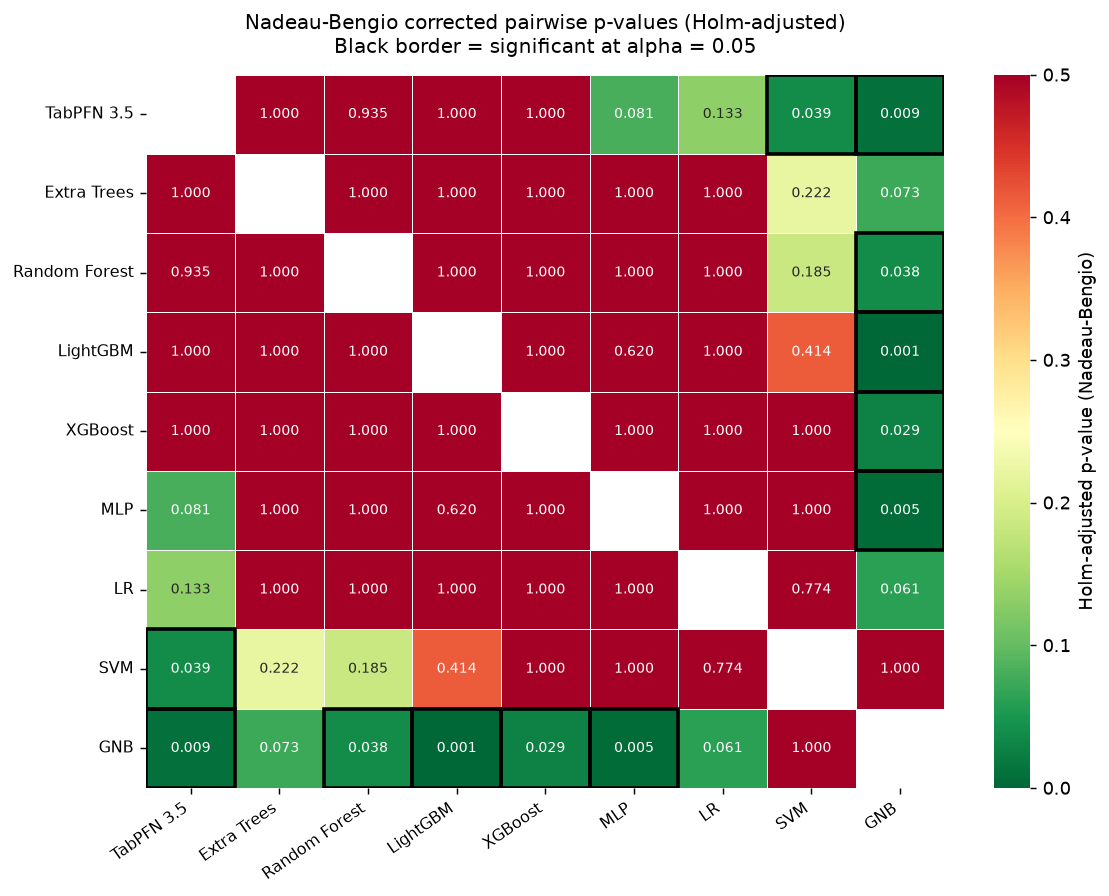

In [5]:
n_m = len(model_order)
pmat = pd.DataFrame(np.ones((n_m, n_m)), index=model_order, columns=model_order)
sig_mat = pd.DataFrame(False, index=model_order, columns=model_order)

for _, row in pw.iterrows():
    a, b = row['Model A'], row['Model B']
    pmat.loc[a, b] = row['p_adj (Holm)']
    pmat.loc[b, a] = row['p_adj (Holm)']
    sig_mat.loc[a, b] = row['Significant']
    sig_mat.loc[b, a] = row['Significant']

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.eye(n_m, dtype=bool)

sns.heatmap(pmat.astype(float), mask=mask, ax=ax,
            cmap='RdYlGn_r', vmin=0, vmax=0.5,
            annot=True, fmt='.3f', annot_kws={'size': 8},
            linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'Holm-adjusted p-value (Nadeau-Bengio)'})

for i in range(n_m):
    for j in range(n_m):
        if i != j and sig_mat.iloc[i, j]:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor='black', lw=2))

ax.set_title('Nadeau-Bengio corrected pairwise p-values (Holm-adjusted)\n'
             'Black border = significant at alpha = 0.05', fontsize=11, pad=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right', fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'nadeau_bengio_pvalue_heatmap.png'), dpi=200, bbox_inches='tight')
plt.show()

## 5  TabPFN vs. every other model — the paper's headline comparison

In [6]:
others = [m for m in model_order if m != 'TabPFN 3.5']
tab_rows = []
for other in others:
    res = nadeau_bengio_ttest(pivot['TabPFN 3.5'].values, pivot[other].values)
    tab_rows.append({
        'vs': other,
        'TabPFN mean': pivot['TabPFN 3.5'].mean(),
        'Other mean': pivot[other].mean(),
        'Delta BA': pivot['TabPFN 3.5'].mean() - pivot[other].mean(),
        't (corrected)': res['t_statistic'],
        'p_raw': res['p_value'],
    })

tab_df = pd.DataFrame(tab_rows)
reject_tab, p_adj_tab, _, _ = multipletests(tab_df['p_raw'], method='holm')
tab_df['p_adj (Holm)'] = p_adj_tab
tab_df['Significant'] = reject_tab
tab_df = tab_df.sort_values('Delta BA', ascending=False).reset_index(drop=True)
for c in ['TabPFN mean', 'Other mean', 'Delta BA', 't (corrected)', 'p_raw', 'p_adj (Holm)']:
    tab_df[c] = tab_df[c].round(4)

print(f"TabPFN 3.5 is significantly different from {tab_df['Significant'].sum()}/{len(others)} "
      f"other models (Nadeau-Bengio, Holm-corrected, alpha=0.05):")
tab_df

TabPFN 3.5 is significantly different from 4/8 other models (Nadeau-Bengio, Holm-corrected, alpha=0.05):


,vs,TabPFN mean,Other mean,Delta BA,t (corrected),p_raw,p_adj (Holm),Significant
0,GNB,0.8734,0.5523,0.3211,5.7569,0.0003,0.0022,True
1,SVM,0.8734,0.6590,0.2144,4.6198,0.0013,0.0088,True
2,LR,0.8734,0.7293,0.1441,3.7012,0.0049,0.0246,True
3,MLP,0.8734,0.7335,0.1400,4.0492,0.0029,0.0173,True
4,XGBoost,0.8734,0.7926,0.0808,2.0040,0.0761,0.2042,False
5,LightGBM,0.8734,0.8041,0.0693,2.0728,0.0681,0.2042,False
6,Random Forest,0.8734,0.8059,0.0676,2.3329,0.0445,0.1781,False
7,Extra Trees,0.8734,0.8275,0.0459,1.3094,0.2229,0.2229,False


**Reading this table**: a positive `Delta BA` means TabPFN scored higher on average across
the 10 seeds. `Significant=True` means that gap survives the Nadeau-Bengio correction and
the Holm multiple-comparison adjustment — i.e. it is not plausibly explained by the
seed-to-seed noise inherent to resampled evaluation, even after accounting for the fact
that the 10 seeds share overlapping training data. A `Significant=False` result does
**not** mean the two models perform identically — with only 10 seeds, the test has
limited power, so a true but small difference can easily fail to reach significance.
It means the evidence in this particular 10-seed sample is not strong enough to rule out
chance as an explanation at the conventional 0.05 threshold.

## 6  Effect size — is a significant difference also a *meaningful* one?

In [7]:
# Standardized mean difference (Cohen's d-style, using the raw per-seed std, not the
# corrected test std) gives an effect-size view independent of sample size / correction.
rows = []
for _, row in pw.iterrows():
    a, b = row['Model A'], row['Model B']
    d_vals = pivot[a].values - pivot[b].values
    cohens_d = d_vals.mean() / d_vals.std(ddof=1) if d_vals.std(ddof=1) > 0 else np.nan
    rows.append({'Model A': a, 'Model B': b, "Cohen's d": cohens_d,
                 'Significant (NB)': row['Significant']})

effect_df = pd.DataFrame(rows)
effect_df['abs_d'] = effect_df["Cohen's d"].abs()
effect_df = effect_df.sort_values('abs_d', ascending=False).drop(columns='abs_d')
effect_df["Cohen's d"] = effect_df["Cohen's d"].round(3)

print("Cohen's d interpretation: |d|<0.2 negligible, 0.2-0.5 small, 0.5-0.8 medium, >0.8 large.")
print("(Rule-of-thumb thresholds from Cohen 1988; not a formal test, just a magnitude guide.)\n")
effect_df.head(15)

Cohen's d interpretation: |d|<0.2 negligible, 0.2-0.5 small, 0.5-0.8 medium, >0.8 large.
(Rule-of-thumb thresholds from Cohen 1988; not a formal test, just a magnitude guide.)



,Model A,Model B,Cohen's d,Significant (NB)
25,LightGBM,GNB,4.657,True
32,MLP,GNB,3.766,True
7,TabPFN 3.5,GNB,3.420,True
29,XGBoost,GNB,2.894,True
20,Random Forest,GNB,2.773,True
6,TabPFN 3.5,SVM,2.745,True
34,LR,GNB,2.544,False
14,Extra Trees,GNB,2.461,False
4,TabPFN 3.5,MLP,2.406,False
5,TabPFN 3.5,LR,2.199,False


## 7  Summary

In [8]:
print('=' * 72)
print('NADEAU-BENGIO CORRECTED RESAMPLED t-TEST — SUMMARY')
print('=' * 72)
print(f'\n{len(pairs)} pairwise comparisons among {n_m} models, 10 seeds each,')
print(f'n_test={N_TEST}, n_train={N_TRAIN} (correction term = 1/10 + {N_TEST}/{N_TRAIN} = '
      f'{1/10 + N_TEST/N_TRAIN:.3f})\n')
print(f'Corrected test:  {n_sig_corrected}/{len(pairs)} pairs significant (Holm, alpha=0.05)')
print(f'Naive t-test:    {n_sig_naive}/{len(pairs)} pairs significant (Holm, alpha=0.05)')
print(f'\nTabPFN 3.5 vs. other models: {tab_df["Significant"].sum()}/{len(others)} significant')
not_sig = tab_df.loc[tab_df['Significant'].astype(bool) == False, 'vs'].tolist()
if not_sig:
    print(f'  Not significantly different from: {", ".join(not_sig)}')
print()
print('Interpretation for the paper: where the corrected and naive tests agree on')
print('significance, that comparison is robust to the choice of statistical test. Where')
print('they disagree, the naive test is the one to distrust -- it does not account for')
print('the shared-training-data correlation across the 10 seeds, and is known to inflate')
print('false-positive rates in exactly this repeated-resampling evaluation design.')

NADEAU-BENGIO CORRECTED RESAMPLED t-TEST — SUMMARY

36 pairwise comparisons among 9 models, 10 seeds each,
n_test=86, n_train=340 (correction term = 1/10 + 86/340 = 0.353)

Corrected test:  6/36 pairs significant (Holm, alpha=0.05)
Naive t-test:    17/36 pairs significant (Holm, alpha=0.05)

TabPFN 3.5 vs. other models: 4/8 significant
  Not significantly different from: XGBoost, LightGBM, Random Forest, Extra Trees

Interpretation for the paper: where the corrected and naive tests agree on
significance, that comparison is robust to the choice of statistical test. Where
they disagree, the naive test is the one to distrust -- it does not account for
the shared-training-data correlation across the 10 seeds, and is known to inflate
false-positive rates in exactly this repeated-resampling evaluation design.
